# Deep Learning
## Practical Deep Learning Tutorial with PyTorch - Tutorial N° 1

### 2025-2026

# Importing necessary libraries

In [99]:
import torch
import torch.nn as nn
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.pyplot import plot, title, axis

# Useful Functions

You will need these 3 functions for this tutorial :

`set_default` to customize figure layouts.

`show_scatterplot` draws a point cloud $X$ in 2-D, each data point has a specific color.

`plot_bases` shows an arrow along the x-axis in red and an arrow along the y-axis in green.

**Warning:** these functions expect tensors stored on the **CPU**.

In [100]:
def set_default(figsize=(10, 10), dpi=100):
    plt.style.use(['dark_background', 'bmh'])
    plt.rc('axes', facecolor='k')
    plt.rc('figure', facecolor='k')
    plt.rc('figure', figsize=figsize, dpi=dpi)

def show_scatterplot(X, title=''):
    x_min=-1.5
    x_max=1.5
    colors = (X-x_min)/(x_max-x_min)
    colors = (colors * 511).short().numpy()
    colors = np.clip(colors, 0, 511)
    colors= colors[:, 0]
    plt.scatter(X[:, 0], X[:, 1], c=colors, s=30)
    plt.title(title)
    plt.axis('off')

def plot_bases(bases, width=0.04):
    plt.arrow(*bases[0], *bases[2], width=width, color=(1,0,0), zorder=10, alpha=1., length_includes_head=True)
    plt.arrow(*bases[1], *bases[3], width=width, color=(0,1,0), zorder=10, alpha=1., length_includes_head=True)

In [101]:
set_default()

PyTorch can run on both the CPU and GPU of a computer.

The CPU is useful for sequential tasks, while the GPU is useful for parallel tasks.

You have to make sure your tensors and models are transferred to the device’s memory. This can be done with the following line of code:

In [102]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

This line creates a variable, called device, that is assigned to the GPU if one is available; otherwise, it defaults to the CPU.

# Data Generation

1. Create a tensor $X$ of 1000 instances in 2-D, drawn from a standard normal distribution, and send it to the device’s memory. Fix the random seed so that your results are reproducible.

In [103]:
torch.manual_seed(42)
X = torch.randn(1000,2,device=device)
X

tensor([[ 1.9269,  1.4873],
        [ 0.9007, -2.1055],
        [ 0.6784, -1.2345],
        ...,
        [ 0.0731,  0.9967],
        [ 1.0238, -1.2133],
        [ 0.9745,  0.4532]])

# Visualizing linear transformations

2. Visualise the original point cloud $X$ together with the canonical basis, using the two functions above.

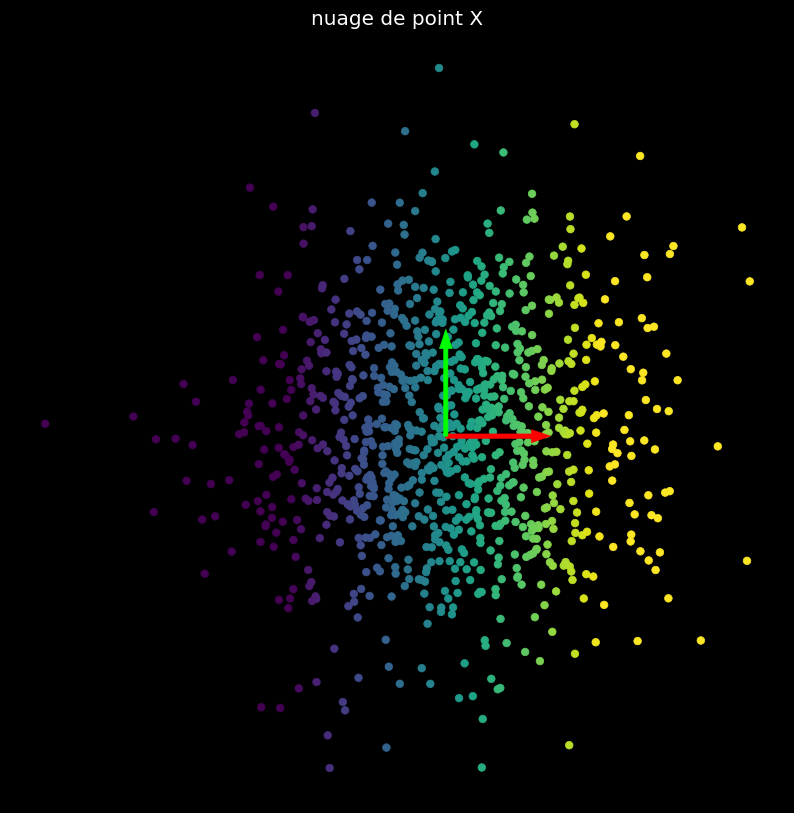

In [104]:
bases = torch.tensor([[0., 0.], [0., 0.], [1., 0.], [0., 1.]])
set_default()
show_scatterplot(X, title = 'nuage de point X')
plot_bases(bases)

3. Explain briefly the Singular Value Decomposition (SVD). For a matrix $W$ of size $(n, m)$, give the shapes of $U$, $S$ and $V$, and the geometric meaning of each factor.

Toute matrice peut se décomposer par la SVD, cette décomposition est utile car elle permet de dégager une matrice pseudo diagonale (S) et surtout V qui par ses colonnes forme les axes principaux lors d'une projection en ACP.

Pour une matrice de taille (n,m) :

U est de taille n*n, U est orthogonale, c'est une rotation 

S est de taille n*m, S est pseudo diagonale, c'est un scaling, étirement.

V est de taille m*m, V est orthogonale, c'est une autre rotation 

Les matrices U et V ne sont pas arbitraires : leurs colonnes sont les
vecteurs propres orthonormés de WW⊤ et W⊤W respectivement.

4. Explain the relation between rotation and orthogonal matrices. Prove that an orthogonal matrix preserves the Euclidean norm of a vector.

Une matrice qui est orthogonale et dont le déterminant est 1 correspond à une rotation.

Une matrice qui est orthogonale et dont le déterminant est -1 correspond à une réflexion.

On prouve qu'une matrice orthogonale préserve la norme euclidienne d'un vecteur : soit Q une matrice orthogonale et x un vecteur : 

$||Qx||^2 = (Qx){^T} * (Qx) = x^T * Q^T * Q * x = x^T * Id * x = x^T * x = ||x||^2$

Et donc :

$||Qx|| = ||x||$


5. Explain the relation between scaling and diagonal matrices.

Faire le scaling d'un vecteur est exactement le multiplier un vecteur par une matrice diagonale.

6. Draw **one** random matrix $W$ of size (2,2).

   a. Compute its SVD with `torch.linalg.svd` and check numerically (with `torch.allclose`) that $W = U \,\mathrm{diag}(S)\, V^T$.

   b. Apply successively to $X$ the three elementary transformations $V^T$, then $\mathrm{diag}(S)$, then $U$. Plot the 4 point clouds (original, after each step) and check that the last one is identical to $Y = XW^T$.

In [105]:
torch.manual_seed(42)
W = torch.randn(2, 2, device=device)
print(W)


tensor([[0.3367, 0.1288],
        [0.2345, 0.2303]])


torch.return_types.linalg_svd(
U=tensor([[-0.7418, -0.6707],
        [-0.6707,  0.7418]]),
S=tensor([0.4777, 0.0991]),
Vh=tensor([[-0.8521, -0.5234],
        [-0.5234,  0.8521]]))
True


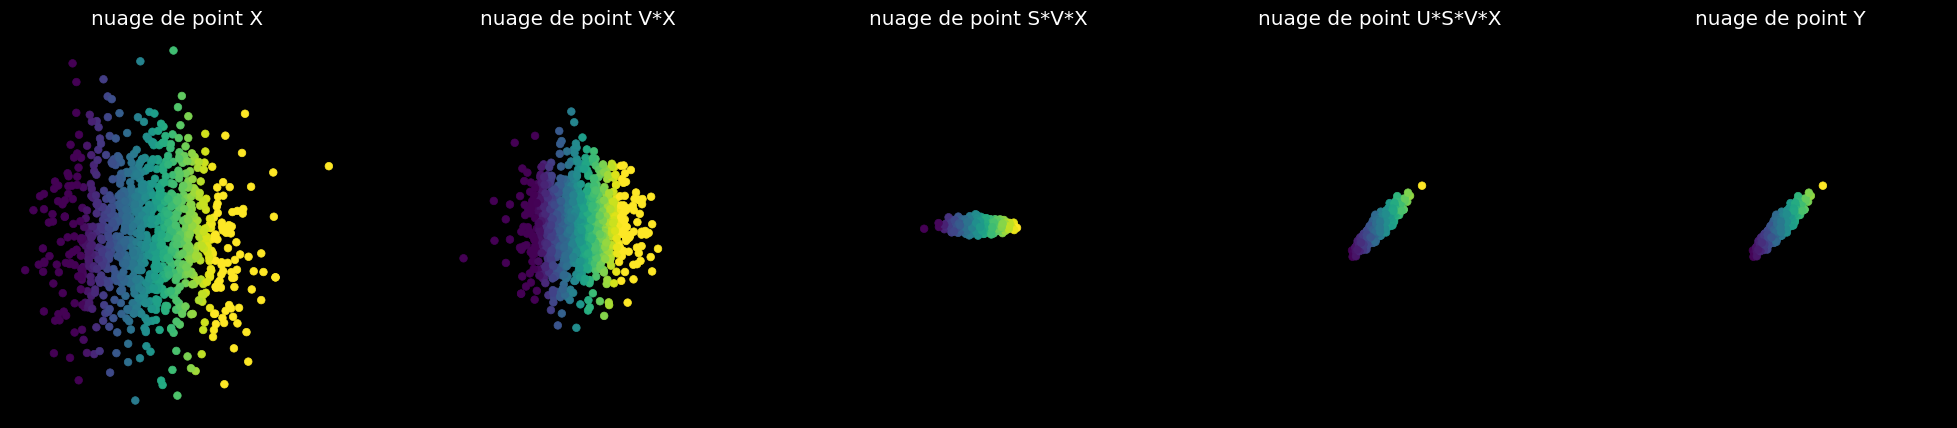

In [106]:
print(torch.linalg.svd(W))
U, S, Vh = torch.linalg.svd(W)
X = torch.randn(1000,2,device=device)
print(torch.allclose(W,U @ torch.diag(S) @ Vh))
plt.figure(figsize=(25, 5))
plt.subplot(1, 5,1)
show_scatterplot(X, title = 'nuage de point X')
X1 = X @ Vh.T
plt.subplot(1, 5, 2)
plt.xlim(-6, 6)
plt.ylim(-6, 6)
show_scatterplot(X1, title = 'nuage de point V*X')
X2 = X1 @ torch.diag(S)
plt.subplot(1, 5, 3)
plt.xlim(-6, 6)
plt.ylim(-6, 6)
show_scatterplot(X2, title = 'nuage de point S*V*X')
X3 = X2 @ U.T
plt.subplot(1, 5, 4)
plt.xlim(-6, 6)
plt.ylim(-6, 6)
show_scatterplot(X3, title = 'nuage de point U*S*V*X')
Y = X @ W.T
plt.subplot(1, 5, 5)
plt.xlim(-6, 6)
plt.ylim(-6, 6)
show_scatterplot(Y, title = 'nuage de point Y')




7. Compute 10 linear transformations using several random matrices $W$ of size (2,2).

    For each transformation, compute the SVD of W, and visualize the transformed point cloud $Y$ with its corresponding singular values $(s_1,s_2)$ in the title.

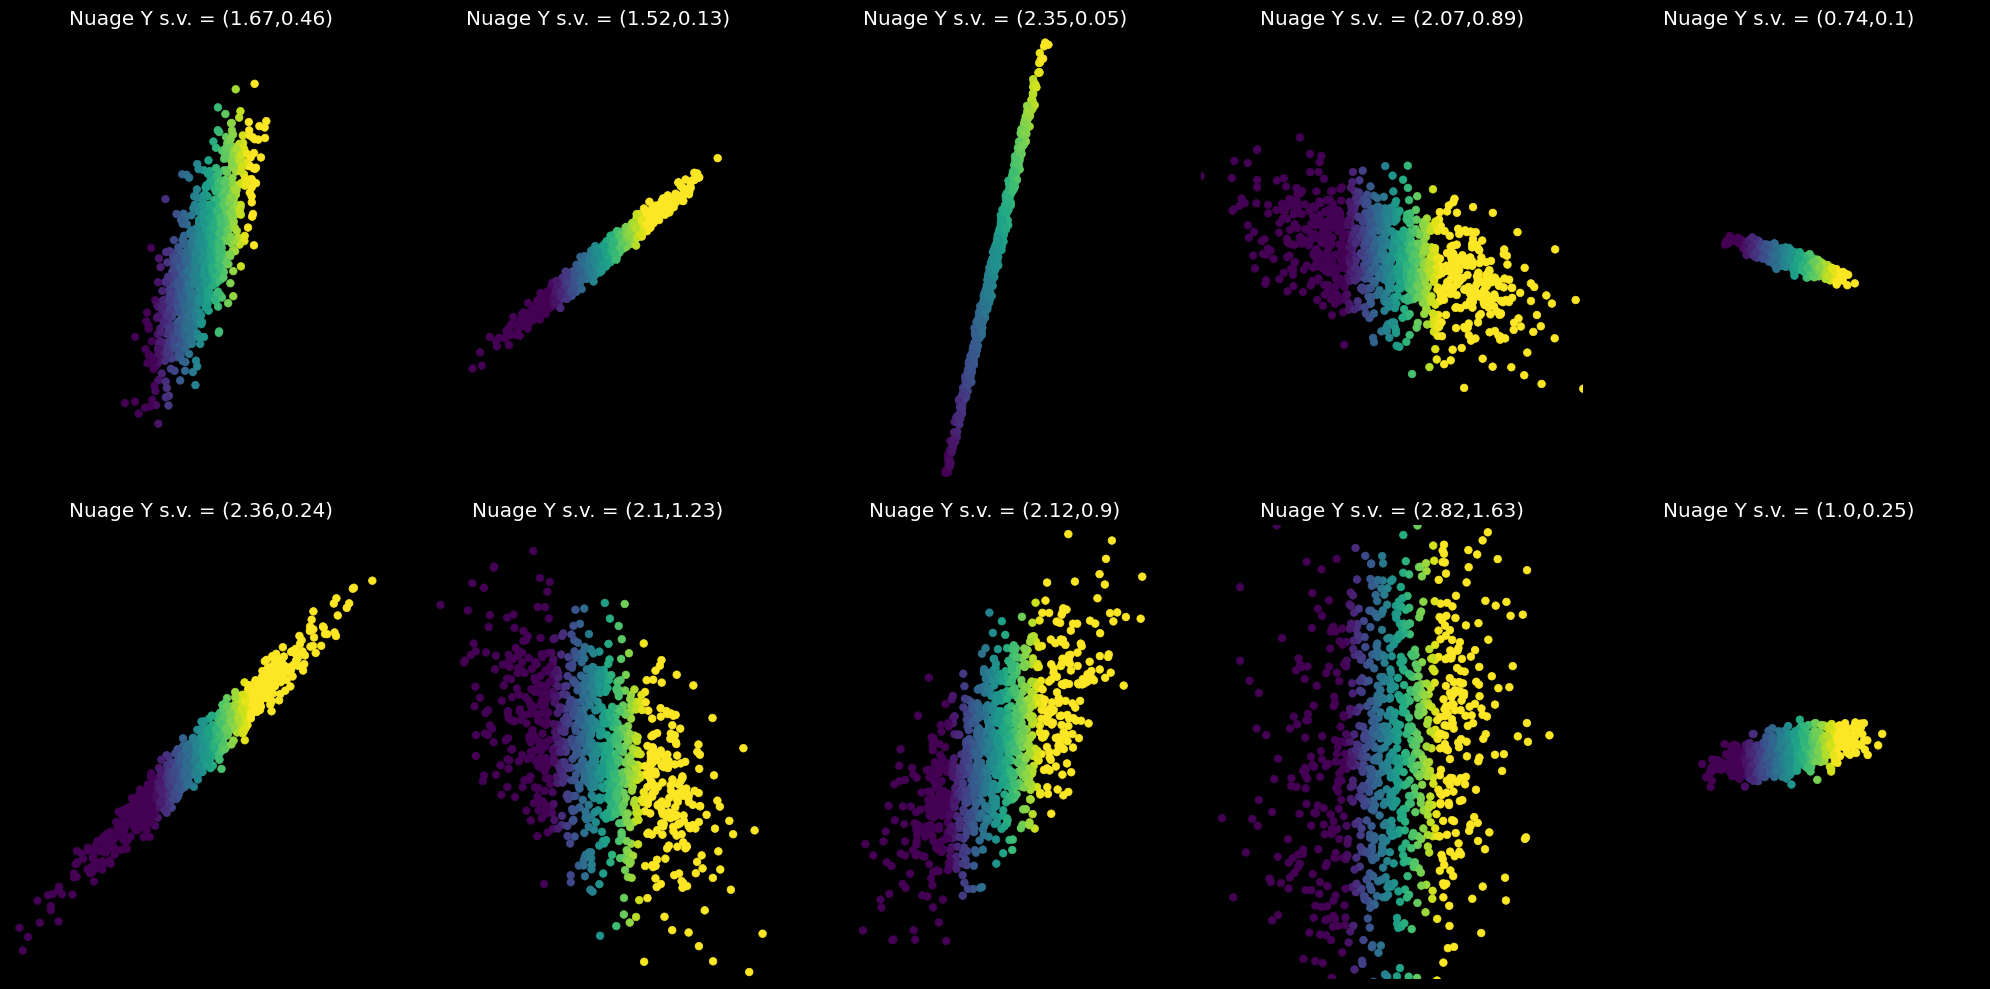

In [107]:
X = torch.randn(1000,2,device=device)
plt.figure(figsize=(20, 10))
detW = []
s1s2 = []
for i in range (0,10):

    W = torch.randn(2, 2, device=device)
    Y = X @ W.T
    U, S, Vh = torch.linalg.svd(W)
    detW.append(torch.linalg.det(W).item())
    plt.subplot(2, 5, i+1)
    s0 = S[0].item()
    s1 =S[1].item()
    s1s2.append(s0*s1)
    show_scatterplot(Y, title = f'Nuage Y s.v. = ({round(s0,2)},{round(s1,2)})')
    plt.xlim(-6, 6)
    plt.ylim(-6, 6)
plt.tight_layout()
plt.show()


8. For each of the 10 matrices of question 7, compute $\det(W)$ and compare $|\det(W)|$ with $s_1 s_2$. What does $|\det(W)|$ represent geometrically? What happens to the point cloud when $\det(W) < 0$? And when $s_2$ is close to 0?

In [108]:
abs_detW = np.abs(detW)
s1s2_np = np.array(s1s2)
np.isclose(s1s2_np , abs_detW, atol = 1e-10000)

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True])

$|\det(W)|$ représente la surface, le volume induit par l'application de la transformation, on prendra plus d'espace si $> 1$ et moins si $< 1$. quand le determinant est négatif le nuage de point voit son orientation changé (il subit une reflexion). quand s2 est proche de 0 il est "comprimé" l prend proportionnellement à s2 de moins en moins de place en largeur, presque à former un axe unique quand s2 tend vers 0.

9. Analyse the results of questions 7 and 8.

Les matrices U et V ne font que des rotations ou réflexions, c'est la matrice S qui représente la surface (dans ce cas) de nos données transformées, on peut anticiper la transformation exclusivement à partir de S1 et S2, leur produit nous donne le déterminant de la matrice S mais aussi de celui de $|\det(W)|$ qui indique a quel point notre nuage de point sera modifié. Quand s2 tend vers 0 on obtient une transformation qui tend vers un nuage de point applati en un seul axe.

# Linear transformation with PyTorch’s nn.Linear class.

10. Compute a similar linear transformation with PyTorch’s `nn.Linear` class:

    a. Set (without training) the weights of the layer to the matrix $W$ of question 6 and the bias to zero. Check that you obtain exactly the same point cloud as in question 6.

    b. Now set a non-zero bias. Visualize the result: which transformation is added?

In [109]:
layer = nn.Linear(2, 2)
layer.weight.data = W.clone()
layer.bias.data = torch.zeros(2)

Y_layer = layer(X)

Y_layer = layer(X)

print(torch.allclose(Y_layer, X @ W.T, atol=1e-5))

True


(-6.0, 6.0)

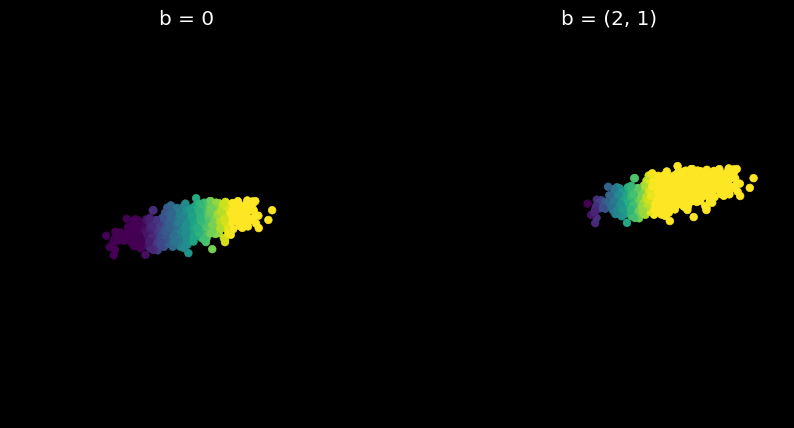

In [110]:

layer.bias.data = torch.tensor([2., 1.],device = device)
Y_bias = layer(X)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
show_scatterplot(Y_layer.detach().cpu(), title='b = 0')
plt.xlim(-6, 6)
plt.ylim(-6, 6)
plt.subplot(1, 2, 2)
show_scatterplot(Y_bias.detach().cpu(), title='b = (2, 1)')
plt.xlim(-6, 6)
plt.ylim(-6, 6)

On voit qu'une translation est ajouté

# Non-linear transformations

11. Plot the graph of the hyperbolic tangent function (tanh). What do you notice about it ?

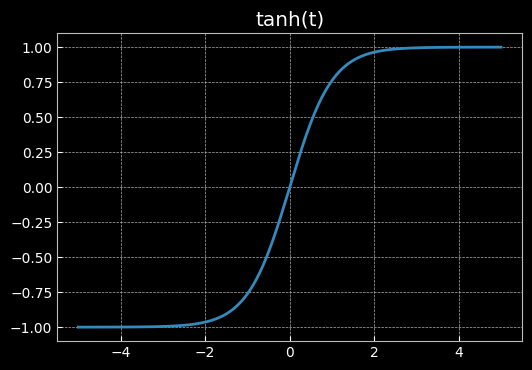

In [111]:
t = torch.linspace(-5, 5, 1000,device=device)
plt.figure(figsize=(6, 4))
plt.plot(t, torch.tanh(t))
plt.title('tanh(t)')
plt.show()

12. For s=1,...,5.
    Compute a linear transformation with PyTorch’s nn.Linear class (the transformation matrix must be a $2*2$ diagonal matrix, with diagonal elements all equal to s), followed by a non-linear transformation using tanh. Visualise the results.

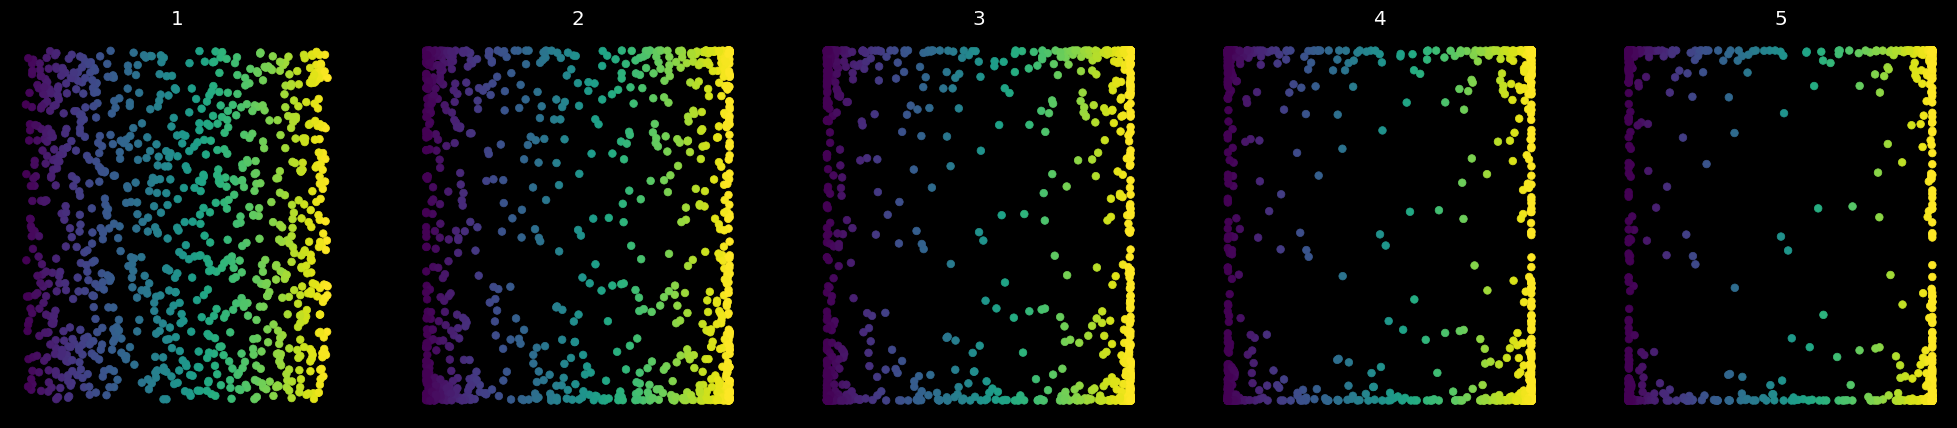

In [112]:
plt.figure(figsize=(25, 5))
for s in range(1, 6):
    layer = nn.Linear(2, 2)
    layer.weight.data = s * torch.eye(2,device=device)
    layer.bias.data = torch.zeros(2,device=device)
    Y = torch.tanh(layer(X))

    plt.subplot(1, 5, s)
    show_scatterplot(Y.detach().cpu(), title=f'{s}')
    plt.xlim(-1.1, 1.1)
    plt.ylim(-1.1, 1.1)
plt.show()

Plus s augmente, plus les points sont envoyés vers +/- 1. Les points s’accumulent sur les bords.

13. Analyse the results. Then redo the experiment for $s = 3$ only, replacing tanh by `sigmoid` and then by `ReLU`. Describe and explain the differences between the three point clouds.

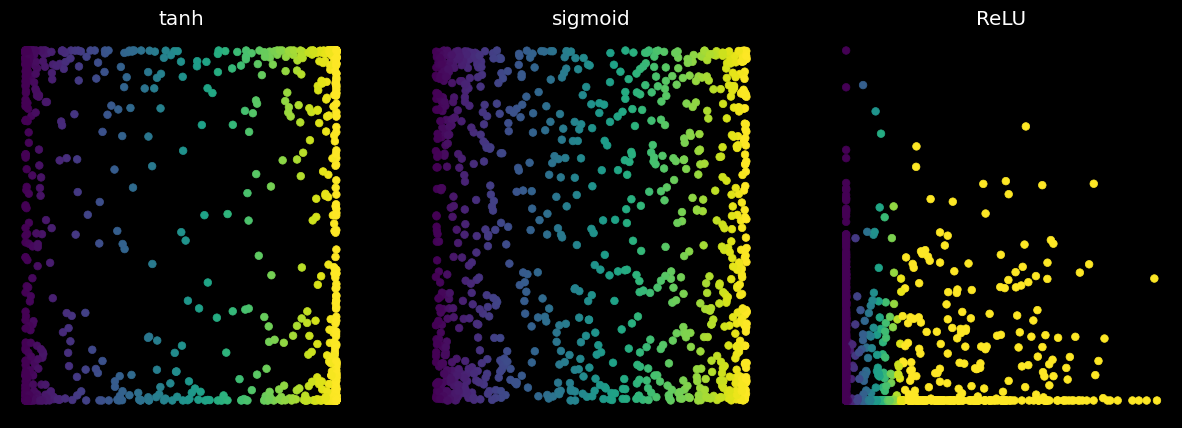

In [113]:
layer = nn.Linear(2, 2)
layer.weight.data = 3 * torch.eye(2,device=device)
layer.bias.data = torch.zeros(2,device=device)
Z = layer(X)

Y_tanh = torch.tanh(Z)
Y_sig = torch.sigmoid(Z)
Y_relu = torch.relu(Z)

plt.figure(figsize=(15, 5))
Yk = [Y_tanh,Y_sig,Y_relu]
name = ['tanh','sigmoid', 'ReLU']
for i in range (1,4):
    plt.subplot(1, 3, i)
    show_scatterplot(Yk[i-1].detach().cpu(), title=name[i-1])
plt.show()

Comme on avait dit tanh accumule les points vers les bords, sigmoid semble faire la même chose mais de manière moins drastique, ils sont moins comprimé vers les bords, ReLU quant à elle semble comprimé seulement une partie des points, les points d'une partie sont complètement ecrasé sur les bords tandis qu'on visualise correctement le reste.

# Transformations performed by a random neural net

14. Compute the network transformation consisting of a linear layer (2 → 5), which performs an affine transformation, followed by a hyperbolic tangent non-linearity, and finally another linear layer (5 → 2). Visualize the transformed point cloud.

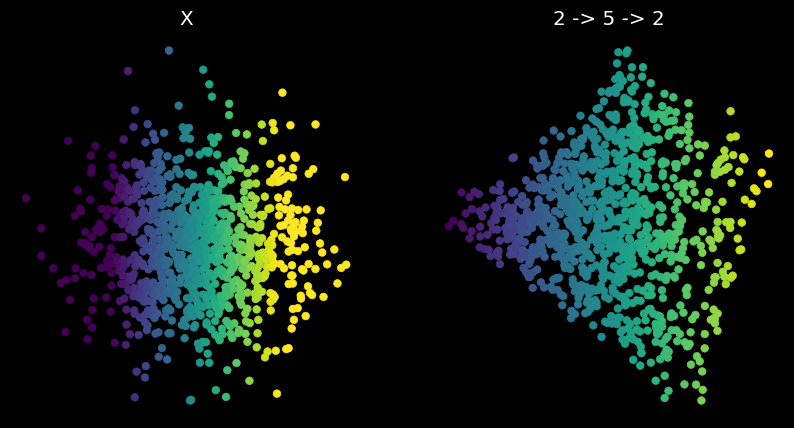

In [114]:
net = nn.Sequential(
    nn.Linear(2, 5,device=device),
    nn.Tanh(),
    nn.Linear(5, 2,device=device))

Y = net(X)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
show_scatterplot(X, title='X')
plt.subplot(1, 2, 2)
show_scatterplot(Y.detach(), title='2 -> 5 -> 2')
plt.show()

15. Answer the above question using a deeper neural network (for instance 5 hidden layers of width 100). Run it several times with different random initializations and comment.

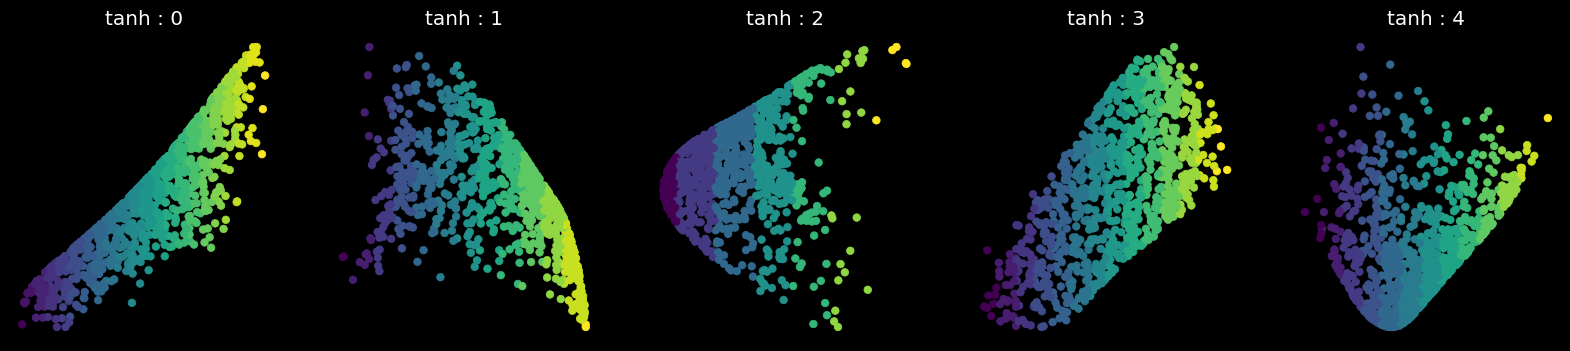

In [115]:
def make_net(depth=5, width=100, activation=nn.Tanh):
    layers = [nn.Linear(2, width,device=device), activation()]
    for j in range(depth - 1):
        layers.append(nn.Linear(width, width,device=device))
        layers.append(activation())
    layers.append(nn.Linear(width, 2,device=device))
    return nn.Sequential(*layers)

plt.figure(figsize=(20, 4))
for i in range(5):
    net = make_net(5, 100, nn.Tanh)
    with torch.no_grad():
        Y = net(X)
    plt.subplot(1, 5, i + 1)
    show_scatterplot(Y, title=f'tanh : {i}')
plt.show()

On obtient des formes différentes, c'est le changement de transformations aléatoires qui en décide, on conserve une assez bonne conceantration des points.

16. a. Repeat question 15 with `ReLU` instead of tanh. What kind of shapes do you observe in the transformed cloud?

    b. Remove all non-linearities from the deep network. Show (by a short computation for 2 layers, then by an experiment) that the network is then equivalent to a single affine transformation, whatever its depth. Conclude on the role of non-linearities.

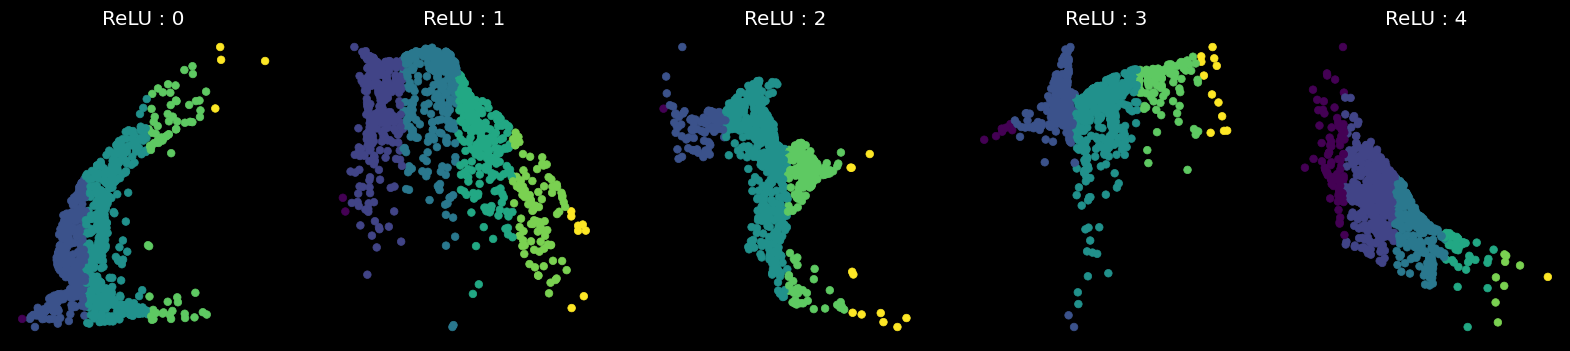

In [116]:
plt.figure(figsize=(20, 4))
for i in range(5):
    net = make_net(5, 100, nn.ReLU)
    with torch.no_grad():
        Y = net(X)
    plt.subplot(1, 5, i + 1)
    show_scatterplot(Y, title=f'ReLU : {i}')
plt.show()

a) On obtient des formes plus différentes, plus variées, moins concentrées et lisse, on peut voir des angles dans les figures.

b) Soit $h = W_1 x + b_1$ puis $y = W_2 h + b_2$. 

Alors :

$y = W_2 (W_1 x + b_1) + b_2 = (W_2 W_1)\,x + (W_2 b_1 + b_2)$

On pose $W = W_2 W_1$ et $b = W_2 b_1 + b_2$ : 

c’est bien $y = Wx + b$

Aucune surprise une composition de tranformation affine reste une transformation affine.

True


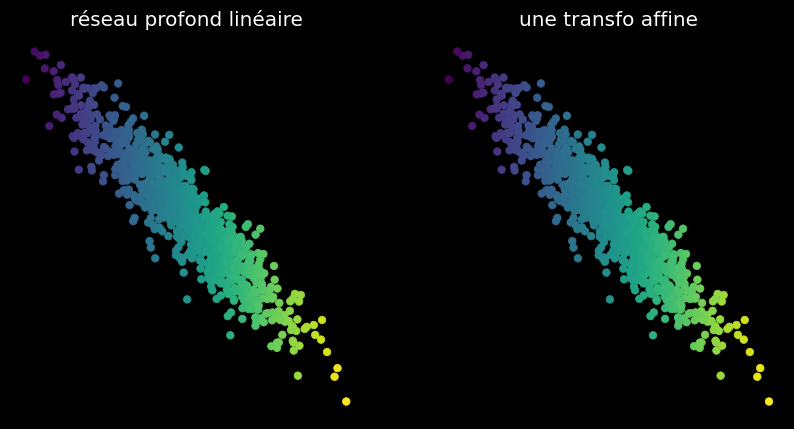

In [117]:
net_lin = nn.Sequential(
    nn.Linear(2, 100),
    nn.Linear(100, 100),
    nn.Linear(100, 100),
    nn.Linear(100, 2)).to(device)

with torch.no_grad():
    Y_deep = net_lin(X)
    W_eq = torch.eye(2,device=device)
    b_eq = torch.zeros(2,device=device)
    for layer in net_lin:
        W_eq = layer.weight @ W_eq
        b_eq = layer.weight @ b_eq + layer.bias

    Y_eq = X @ W_eq.T + b_eq

print(torch.allclose(Y_deep, Y_eq, atol=1e-4))

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
show_scatterplot(Y_deep, title='réseau profond linéaire')
plt.subplot(1, 2, 2)
show_scatterplot(Y_eq, title='une transfo affine')
plt.show()

Empiler des couches qui sont seulement linéaire n'apporte rien, c'est inutile, une seule suffit. La non linéarité nous permet de casser la forme du nuage, et donne une importance à la profondeur du nombre de couches.